In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("semaaabumousa/athlete-eventscsv")
print("Path to dataset files:", path)

!ls /root/.cache/kagglehub/datasets/semaaabumousa/athlete-eventscsv/versions/1

# Commented out IPython magic to ensure Python compatibility.
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams[
    "figure.dpi"
] = 100
pd.set_option("display.max_columns", None)

# %matplotlib inline

df = pd.read_csv(os.path.join(path, 'athlete_events.csv'))
df.head()

"""### Quick  check before diving into questions"""

print("Shape:", df.shape)
df.info()

df.isnull().sum()/df.shape[
    0
]

# Medal is expected to be mostly missing (only top-3 per event get one) —so null values mea no medal
df[
    "Medal"
].value_counts(dropna=False)



import numpy as np

Path to dataset files: C:\Users\usifa\.cache\kagglehub\datasets\semaaabumousa\athlete-eventscsv\versions\1


'ls' is not recognized as an internal or external command,
operable program or batch file.


Shape: (271116, 15)
<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 56.6 MB


'##Q6. How has the gender balance (proportion of male vs. female athletes) changed from 1896 to today?**\n* hint: across time so best plot could be a line plot\nthe ratio is so near to become 1:1\n\n##Q7. Does host-country advantage show up in the data — do host nations win more medals in the year they host?\n** take Germany as example and compute number of medals each year , highlighting the host year\n\nYES\n\n\n\n##Q8. Is there a relationship between an athlete\'s height and the sport they compete in (e.g., basketball vs. gymnastics)?\n--- Yes\n##  · Ranking / "Who Dominates"\n**Q10. Which countries (NOC) have won the most total medals across all Games?**\n\n**Q11. Which sports/events does each dominant country specialize in?** # take two dominant countries as example**Q12. Which sport has the widest range of athlete ages, and which has the narrowest (most age-restrictive in practice)?**\nconsider sorting sports by IQR and showing only the extremes.*\n\n---\n## Wrap-up\n\nOnce you\'

# Data Cleaning


In [65]:
print("Shape:", df.shape)
df.info()

# Medal is expected to be mostly missing (only top-3 per event get one) —so null values means no medal
df["Medal"].value_counts(dropna=False)

Shape: (271116, 15)
<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 56.6 MB


Medal
NaN       231333
Gold       13372
Bronze     13295
Silver     13116
Name: count, dtype: int64

In [66]:
df.isnull().sum()/df.shape[0]


ID        0.000000
Name      0.000000
Sex       0.000000
Age       0.034944
Height    0.221938
Weight    0.231912
Team      0.000000
NOC       0.000000
Games     0.000000
Year      0.000000
Season    0.000000
City      0.000000
Sport     0.000000
Event     0.000000
Medal     0.853262
dtype: float64

In [67]:
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### Sex and missed_age relation

<Axes: xlabel='Sex', ylabel='age_is_null'>

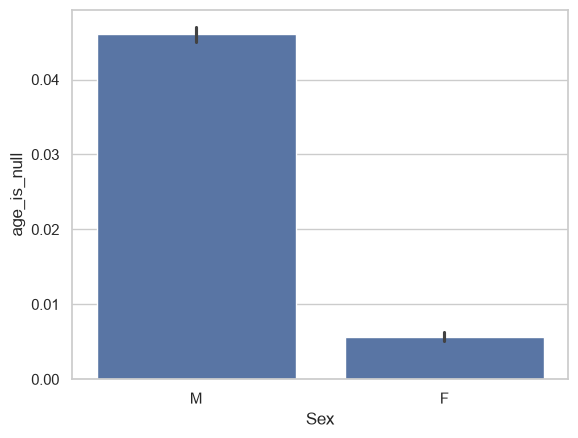

In [ ]:
df['age_is_null']=df['Age'].isnull()
sns.barplot(data=df,x='Sex',y='age_is_null')

In [80]:
df.groupby('Sex')['age_is_null'].mean()


Sex
F    0.005690
M    0.046034
Name: age_is_null, dtype: float64

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34],
 [Text(0, 0, '1896'),
  Text(1, 0, '1900'),
  Text(2, 0, '1904'),
  Text(3, 0, '1906'),
  Text(4, 0, '1908'),
  Text(5, 0, '1912'),
  Text(6, 0, '1920'),
  Text(7, 0, '1924'),
  Text(8, 0, '1928'),
  Text(9, 0, '1932'),
  Text(10, 0, '1936'),
  Text(11, 0, '1948'),
  Text(12, 0, '1952'),
  Text(13, 0, '1956'),
  Text(14, 0, '1960'),
  Text(15, 0, '1964'),
  Text(16, 0, '1968'),
  Text(17, 0, '1972'),
  Text(18, 0, '1976'),
  Text(19, 0, '1980'),
  Text(20, 0, '1984'),
  Text(21, 0, '1988'),
  Text(22, 0, '1992'),
  Text(23, 0, '1994'),
  Text(24, 0, '1996'),
  Text(25, 0, '1998'),
  Text(26, 0, '2000'),
  Text(27, 0, '2002'),
  Text(28, 0, '2004'),
  Text(29, 0, '2006'),
  Text(30, 0, '2008'),
  Text(31, 0, '2010'),
  Text(32, 0, '2012'),
  Text(33, 0, '2014'),
  Text(34, 0, '2016')])

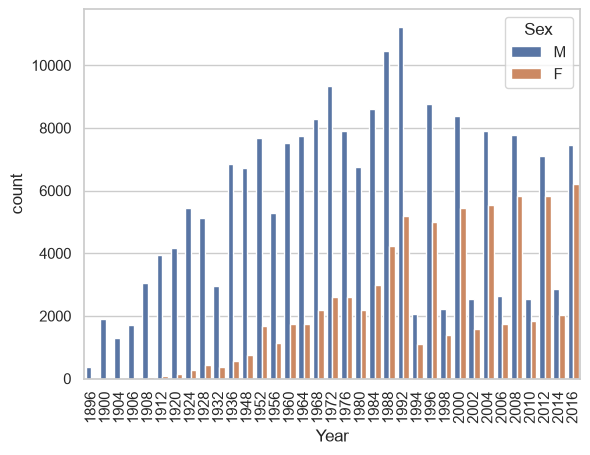

In [70]:
sns.countplot(data=df,x='Year',hue='Sex')
plt.xticks(rotation=90)
#in the first years women were not partcipate in the olympics and the ratio between women and men until now did not become 1:1 
# always men are more so it make sense that the missed age in men is more

### Year and missed_age relation

In [71]:
df.groupby('Year')['age_is_null'].mean()

Year
1896    0.428947
1900    0.408058
1904    0.210607
1906    0.428736
1908    0.209287
1912    0.038614
1920    0.196878
1924    0.200597
1928    0.172766
1932    0.099368
1936    0.028780
1948    0.157219
1952    0.029600
1956    0.099161
1960    0.023931
1964    0.005907
1968    0.011261
1972    0.008027
1976    0.004951
1980    0.020924
1984    0.018640
1988    0.007495
1992    0.002681
1994    0.000633
1996    0.000581
1998    0.000555
2000    0.000072
2002    0.000000
2004    0.000000
2006    0.000000
2008    0.000147
2010    0.000000
2012    0.000000
2014    0.000000
2016    0.000000
Name: age_is_null, dtype: float64

<Axes: xlabel='Year', ylabel='age_is_null'>

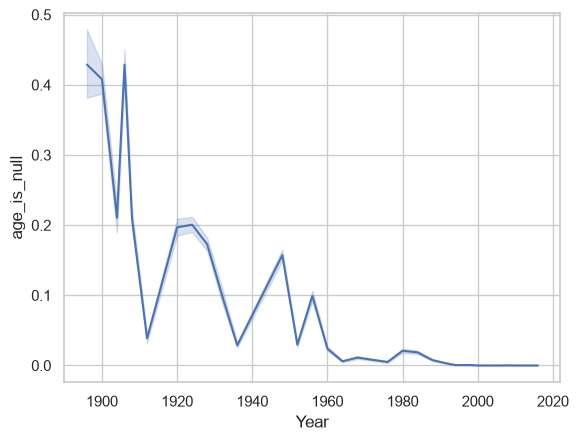

In [72]:
sns.lineplot(data=df,x='Year',y='age_is_null')
#age clearly were affected by the year in the first years age was highly missed but now the percent is approxmitly zero

### season and missed_age relation

In [73]:
df.groupby('Season')['age_is_null'].mean()

Season
Summer    0.041289
Winter    0.005869
Name: age_is_null, dtype: float64

<Axes: xlabel='Season', ylabel='age_is_null'>

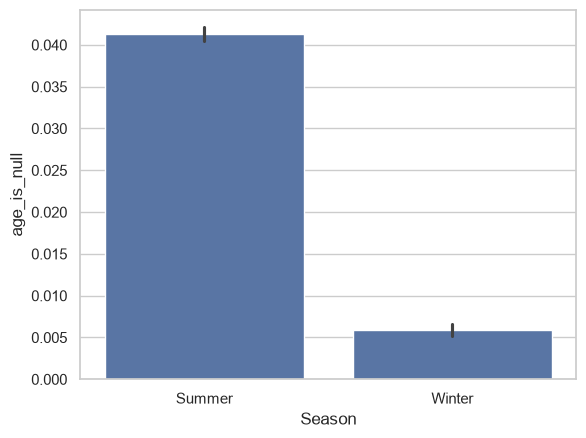

In [88]:
sns.barplot(data=df,x='Season',y='age_is_null')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34],
 [Text(0, 0, '1896'),
  Text(1, 0, '1900'),
  Text(2, 0, '1904'),
  Text(3, 0, '1906'),
  Text(4, 0, '1908'),
  Text(5, 0, '1912'),
  Text(6, 0, '1920'),
  Text(7, 0, '1924'),
  Text(8, 0, '1928'),
  Text(9, 0, '1932'),
  Text(10, 0, '1936'),
  Text(11, 0, '1948'),
  Text(12, 0, '1952'),
  Text(13, 0, '1956'),
  Text(14, 0, '1960'),
  Text(15, 0, '1964'),
  Text(16, 0, '1968'),
  Text(17, 0, '1972'),
  Text(18, 0, '1976'),
  Text(19, 0, '1980'),
  Text(20, 0, '1984'),
  Text(21, 0, '1988'),
  Text(22, 0, '1992'),
  Text(23, 0, '1994'),
  Text(24, 0, '1996'),
  Text(25, 0, '1998'),
  Text(26, 0, '2000'),
  Text(27, 0, '2002'),
  Text(28, 0, '2004'),
  Text(29, 0, '2006'),
  Text(30, 0, '2008'),
  Text(31, 0, '2010'),
  Text(32, 0, '2012'),
  Text(33, 0, '2014'),
  Text(34, 0, '2016')])

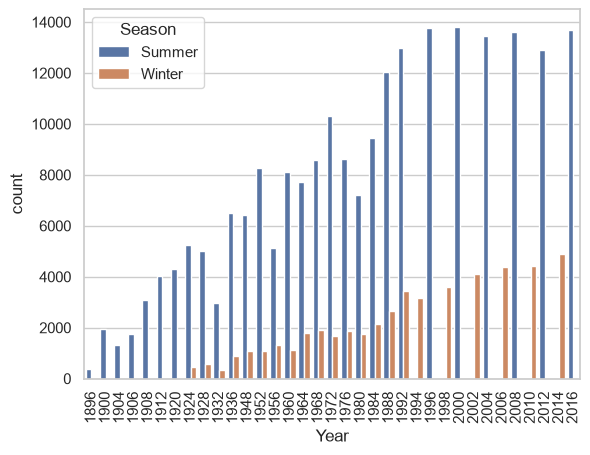

In [ ]:
sns.countplot(data=df,x='Year',hue='Season')
plt.xticks(rotation=90)
# Winter Games make the gap in missing age data reasonable

### relation between missed_age and city

In [81]:
top_cities= df['City'].value_counts().head(10).index
filtered_cities_df = df[df['City'].isin(top_cities)]

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Barcelona'),
  Text(1, 0, 'London'),
  Text(2, 0, 'Los Angeles'),
  Text(3, 0, 'Sydney'),
  Text(4, 0, 'Atlanta'),
  Text(5, 0, 'Beijing'),
  Text(6, 0, 'Rio de Janeiro'),
  Text(7, 0, 'Athina'),
  Text(8, 0, 'Munich'),
  Text(9, 0, 'Seoul')])

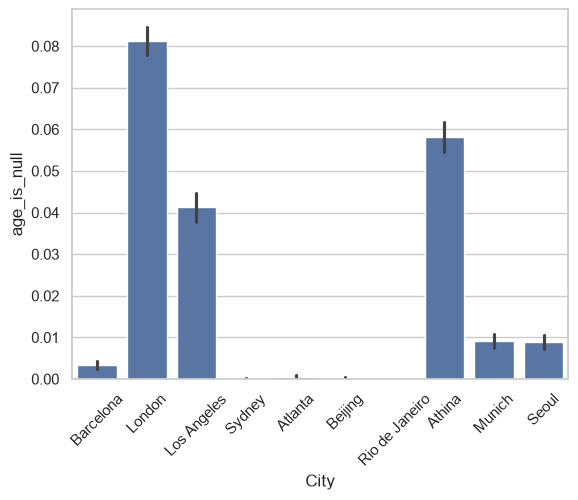

In [76]:
sns.barplot(data=filtered_cities_df,x='City', y='age_is_null')
plt.xticks(rotation=45)
# there is a clear relation between the host City and the missing age data. Cities like London and Athina have significantly higher missing age rates
#  because they hosted earlier Olympic Games,whereas modern host cities like Beijing and Rio have almost zero missing age values

#### The missing values in the 'Age' column can be classified as Missing at Random (MAR), because the missingness systematically depends on other observed variables like 'Year' and 'City' rather than the missing age values themselves.

In [77]:
df['Age'] = df['Age'].fillna(df.groupby(['Sport', 'Sex'])['Age'].transform('median'))

# Func for Relations of missing values with (Year , season , gender ,  city)

In [ ]:
def plot_numerical_relationships(df, num_col):

    df[f'{num_col}_is_null']=df[num_col].isnull()
    filtered_cities_df = df[df['City'].isin(top_cities)]


    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
    fig.suptitle(f'Exploratory Analysis for {num_col}')
    
    sns.lineplot(data=df, x='Year', y=f'{num_col}_is_null', ax=axes[0, 0])
    axes[0, 0].set_title(f'{num_col} over Years')
    
    sns.barplot(data=df, x='Season', y=f'{num_col}_is_null', ax=axes[0, 1])
    axes[0, 1].set_title(f'{num_col} by Season')
    
    sns.barplot(data=df, x='Sex', y=f'{num_col}_is_null', ax=axes[1, 0])
    axes[1, 0].set_title(f'{num_col} Distribution by Gender')
    
    sns.barplot(data=filtered_cities_df, x='City', y=f'{num_col}_is_null', ax=axes[1, 1])
    axes[1, 1].set_title(f'Mean {num_col} across Top 10 Cities')
    axes[1, 1].tick_params(axis='x', rotation=45)
    
    plt.show()

    #df['age_is_null']=df['Age'].isnull()


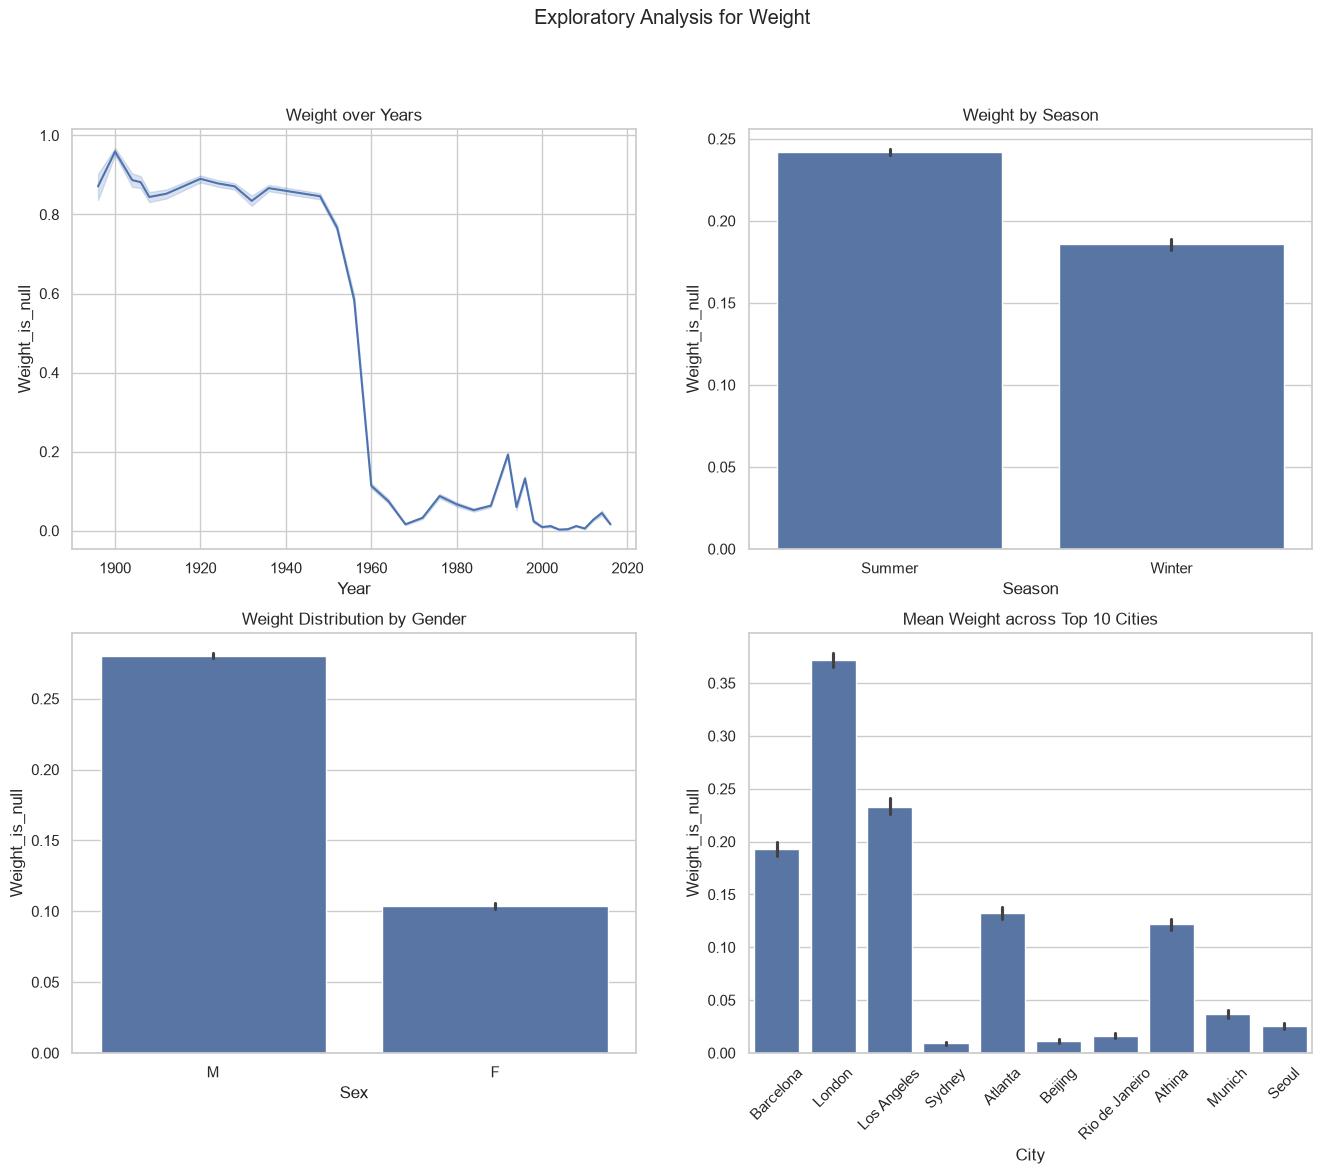

In [92]:
plot_numerical_relationships(df,'Weight')

In [94]:
df['weight'] = df['Weight'].fillna(df.groupby(['Sport', 'Sex'])['Weight'].transform('median'))

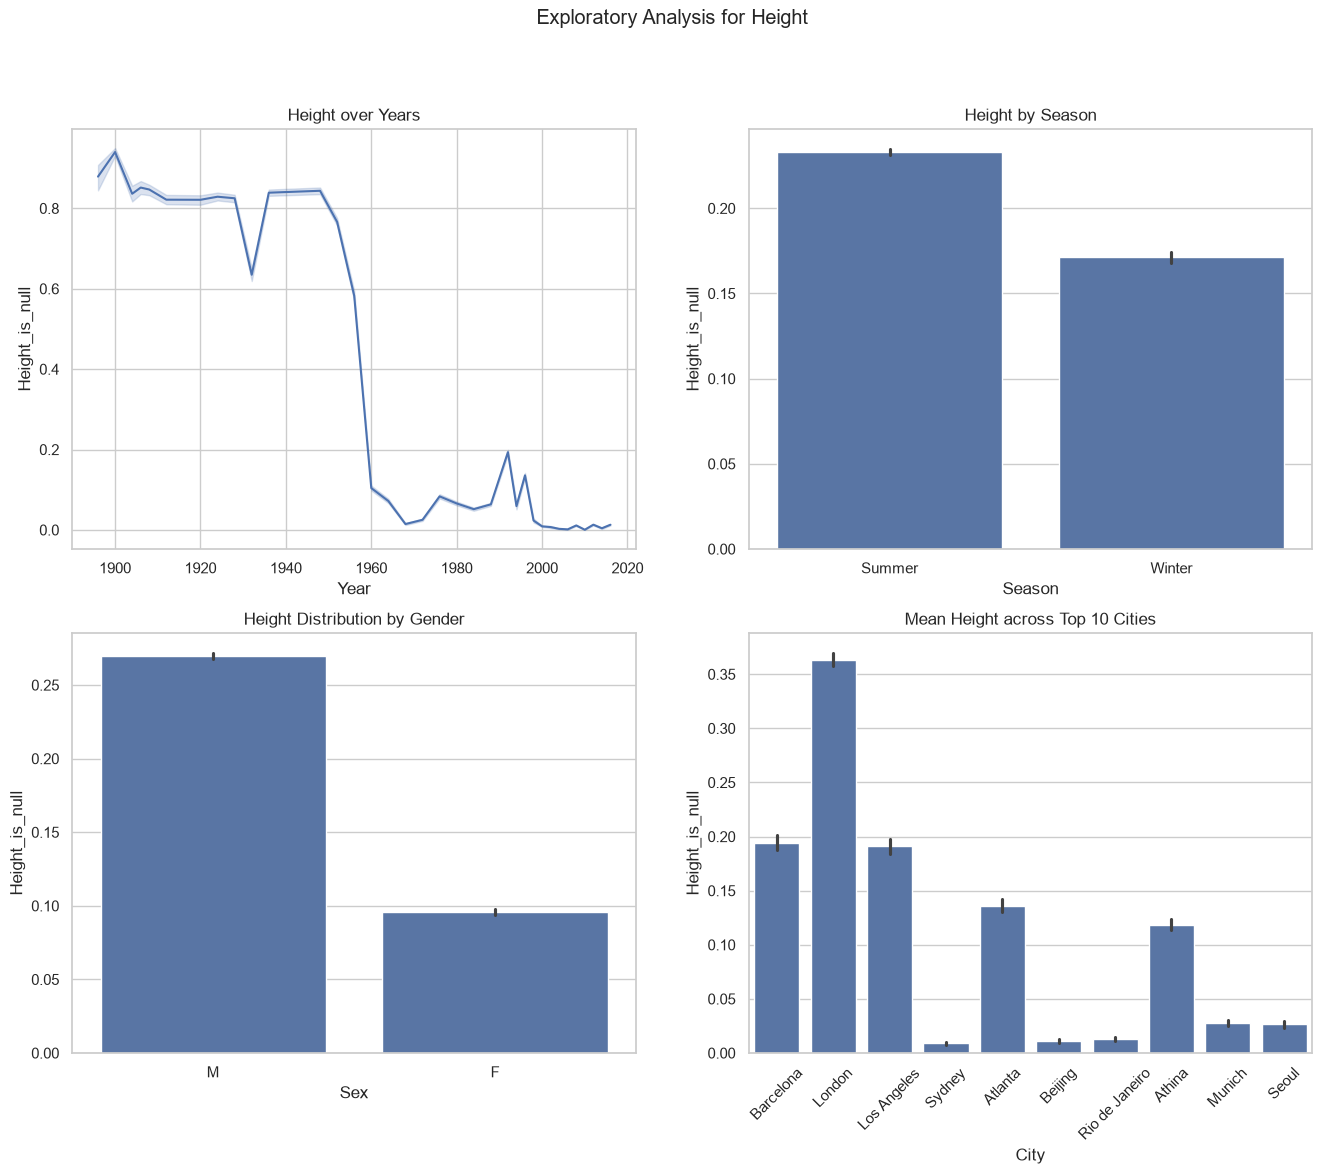

In [93]:
plot_numerical_relationships(df,'Height')

In [95]:
df['Height'] = df['Height'].fillna(df.groupby(['Sport', 'Sex'])['Height'].transform('median'))

# The Insights
- Missing values (nulls) in numerical attributes (like Age, Height, Weight) 
- decrease over the years as Olympic organization and data recording improved.
- Furthermore, null counts are consistently higher among male athletes in the earlier,
- poorly organized years simply because female participation was nearly non-existent 
- at the inception of the games. As time progressed, newer host nations and 
- more structured modern organizations significantly reduced missing data rates due to better tracking.